# Household Energy Consumption Analysis and Prediction

In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [88]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.cluster import KMeans

### Loading Data

In [89]:
df = pd.read_csv('household_power_consumption.txt', sep=';', na_values=['?'], low_memory=False)

In [90]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [91]:
df.shape

(2075259, 9)

### Preprocessing

In [92]:
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')

In [93]:
df.drop(columns=['Date', 'Time'], inplace=True)

In [94]:
df.set_index('Datetime', inplace=True)

In [95]:
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [96]:
df.isna().sum()

Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [97]:
df.ffill(inplace=True)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0
...,...,...,...,...,...,...,...
2010-11-26 20:58:00,0.946,0.000,240.43,4.0,0.0,0.0,0.0
2010-11-26 20:59:00,0.944,0.000,240.00,4.0,0.0,0.0,0.0
2010-11-26 21:00:00,0.938,0.000,239.82,3.8,0.0,0.0,0.0


### Hourly Resampling and Feature Extraction

In [98]:
df_hourly = df.resample('h').mean()

In [99]:
df_hourly.ffill(inplace=True)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667
...,...,...,...,...,...,...,...
2010-11-26 17:00:00,1.725900,0.061400,237.069667,7.216667,0.0,0.000000,12.866667
2010-11-26 18:00:00,1.573467,0.053700,237.531833,6.620000,0.0,0.000000,0.000000
2010-11-26 19:00:00,1.659333,0.060033,236.741000,7.056667,0.0,0.066667,0.000000


In [100]:
df_hourly['Hour'] = df_hourly.index.hour
df_hourly['DayOfWeek'] = df_hourly.index.dayofweek
df_hourly['Month'] = df_hourly.index.month
df_hourly['Is_Weekend'] = (df_hourly['DayOfWeek'] >= 5).astype(int)

In [101]:
df_hourly.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,DayOfWeek,Month,Is_Weekend
Datetime,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,17,5,12,1
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,18,5,12,1
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,19,5,12,1
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,20,5,12,1
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,21,5,12,1


In [102]:
df_hourly.shape

(34589, 11)

### Correlation Analysis

In [103]:
p_corr = df_hourly.corr(method='pearson')['Global_active_power']
s_corr = df_hourly.corr(method='spearman')['Global_active_power']
k_corr = df_hourly.corr(method='kendall')['Global_active_power']

In [104]:
corr_df = pd.DataFrame({'Pearson': p_corr, 'Spearman': s_corr, 'Kendall': k_corr}).drop('Global_active_power')
corr_df

,Pearson,Spearman,Kendall
Global_reactive_power,0.309512,0.217569,0.147667
Voltage,-0.374507,-0.339157,-0.230576
Global_intensity,0.999414,0.998110,0.968364
Sub_metering_1,0.496978,0.442825,0.354121
Sub_metering_2,0.440434,0.190755,0.136713
Sub_metering_3,0.696571,0.691638,0.511380
Hour,0.329218,0.343216,0.232937
DayOfWeek,0.073177,0.055720,0.039838
Month,-0.040296,-0.054091,-0.040549
Is_Weekend,0.092545,0.068024,0.055543


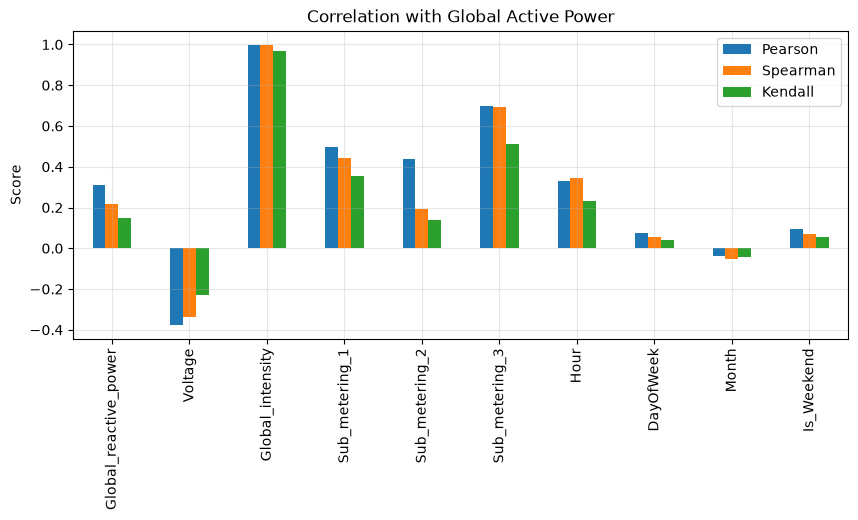

In [105]:
corr_df.plot(kind='bar', figsize=(10, 4))
plt.title('Correlation with Global Active Power')
plt.ylabel('Score')
plt.grid(True, alpha=0.3)
plt.show()

### Exploratory Plots

In [106]:
hourly_power = df_hourly.groupby('Hour')['Global_active_power'].mean()

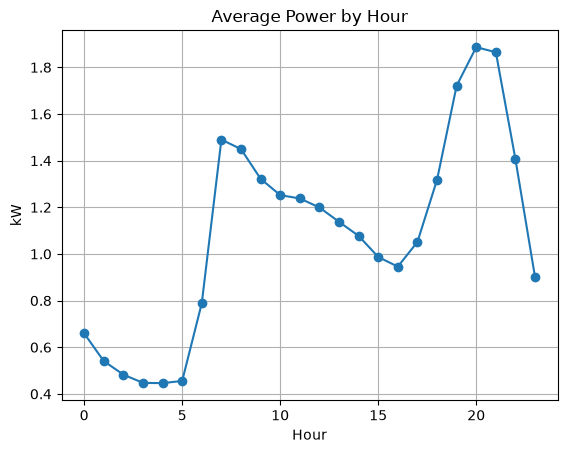

In [107]:
plt.plot(hourly_power.index, hourly_power.values, marker='o')
plt.title('Average Power by Hour')
plt.xlabel('Hour')
plt.ylabel('kW')
plt.grid(True)
plt.show()

In [108]:
sub_hourly = df_hourly.groupby('Hour')[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].mean()

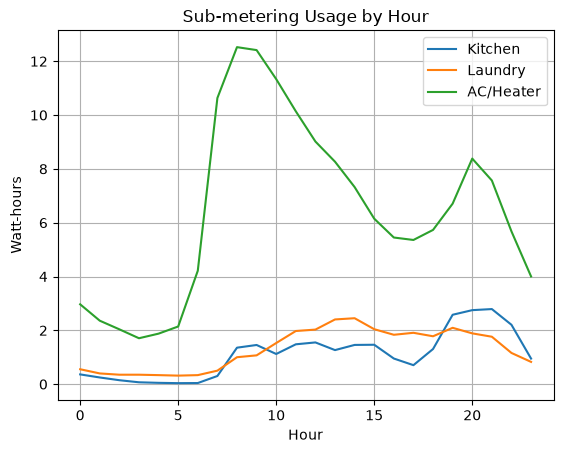

In [109]:
plt.plot(sub_hourly['Sub_metering_1'], label='Kitchen')
plt.plot(sub_hourly['Sub_metering_2'], label='Laundry')
plt.plot(sub_hourly['Sub_metering_3'], label='AC/Heater')
plt.title('Sub-metering Usage by Hour')
plt.xlabel('Hour')
plt.ylabel('Watt-hours')
plt.legend()
plt.grid(True)
plt.show()

### Data Splitting and Scaling

In [110]:
features = ['Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Hour', 'DayOfWeek', 'Month', 'Is_Weekend']
X = df_hourly[features]
y = df_hourly['Global_active_power']

In [111]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [112]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### 1. Linear Regression

In [113]:
lr = LinearRegression()
lr.fit(X_train_s, y_train)
lr_pred = lr.predict(X_test_s)

In [114]:
lr_r2 = r2_score(y_test, lr_pred)
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

print('Linear Regression R2:', lr_r2)
print('Linear Regression MAE:', lr_mae)
print('Linear Regression RMSE:', lr_rmse)

Linear Regression R2: 0.9992341933794977
Linear Regression MAE: 0.012989658807664124
Linear Regression RMSE: 0.020223644997601542


### 2. Ridge Regression

In [115]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_s, y_train)
ridge_pred = ridge.predict(X_test_s)

In [116]:
ridge_r2 = r2_score(y_test, ridge_pred)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))

print('Ridge R2:', ridge_r2)
print('Ridge MAE:', ridge_mae)
print('Ridge RMSE:', ridge_rmse)

Ridge R2: 0.9992336173752655
Ridge MAE: 0.012993004380203576
Ridge RMSE: 0.02023124921202108


### 3. Lasso Regression

In [117]:
lasso = Lasso(alpha=0.001)
lasso.fit(X_train_s, y_train)
lasso_pred = lasso.predict(X_test_s)

In [118]:
lasso_r2 = r2_score(y_test, lasso_pred)
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))

print('Lasso R2:', lasso_r2)
print('Lasso MAE:', lasso_mae)
print('Lasso RMSE:', lasso_rmse)

Lasso R2: 0.999183028237053
Lasso MAE: 0.01343702915610738
Lasso RMSE: 0.020888314512525978


### 4. Decision Tree Regressor

In [119]:
dt = DecisionTreeRegressor(max_depth=8, random_state=42)
dt.fit(X_train_s, y_train)
dt_pred = dt.predict(X_test_s)

In [120]:
dt_r2 = r2_score(y_test, dt_pred)
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))

print('Decision Tree R2:', dt_r2)
print('Decision Tree MAE:', dt_mae)
print('Decision Tree RMSE:', dt_rmse)

Decision Tree R2: 0.9986157687290041
Decision Tree MAE: 0.018600465942592175
Decision Tree RMSE: 0.027189686672575247


### 5. Random Forest Regressor

In [121]:
rf = RandomForestRegressor(n_estimators=40, max_depth=8, random_state=42)
rf.fit(X_train_s, y_train)
rf_pred = rf.predict(X_test_s)

In [122]:
rf_r2 = r2_score(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print('Random Forest R2:', rf_r2)
print('Random Forest MAE:', rf_mae)
print('Random Forest RMSE:', rf_rmse)

Random Forest R2: 0.998892666155797
Random Forest MAE: 0.01594748767034268
Random Forest RMSE: 0.024318633169580064


### Model Comparison

In [123]:
results_data = {
    'Model': ['Linear Regression', 'Ridge', 'Lasso', 'Decision Tree', 'Random Forest'],
    'MAE': [lr_mae, ridge_mae, lasso_mae, dt_mae, rf_mae],
    'RMSE': [lr_rmse, ridge_rmse, lasso_rmse, dt_rmse, rf_rmse],
    'R2': [lr_r2, ridge_r2, lasso_r2, dt_r2, rf_r2]
}
res_df = pd.DataFrame(results_data)
res_df

,Model,MAE,RMSE,R2
0,Linear Regression,0.012990,0.020224,0.999234
1,Ridge,0.012993,0.020231,0.999234
2,Lasso,0.013437,0.020888,0.999183
3,Decision Tree,0.018600,0.027190,0.998616
4,Random Forest,0.015947,0.024319,0.998893


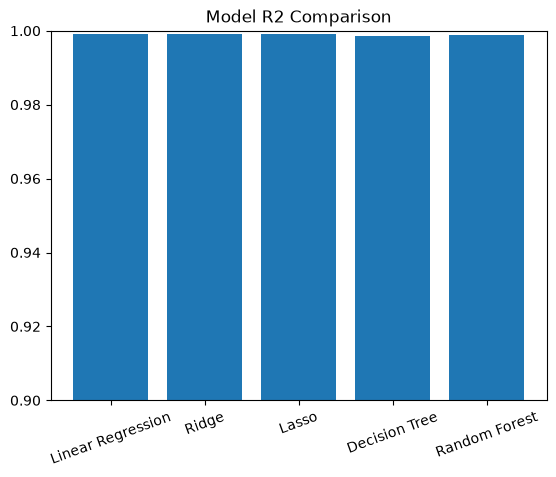

In [124]:
plt.bar(res_df['Model'], res_df['R2'])
plt.title('Model R2 Comparison')
plt.ylim(0.9, 1.0)
plt.xticks(rotation=20)
plt.show()

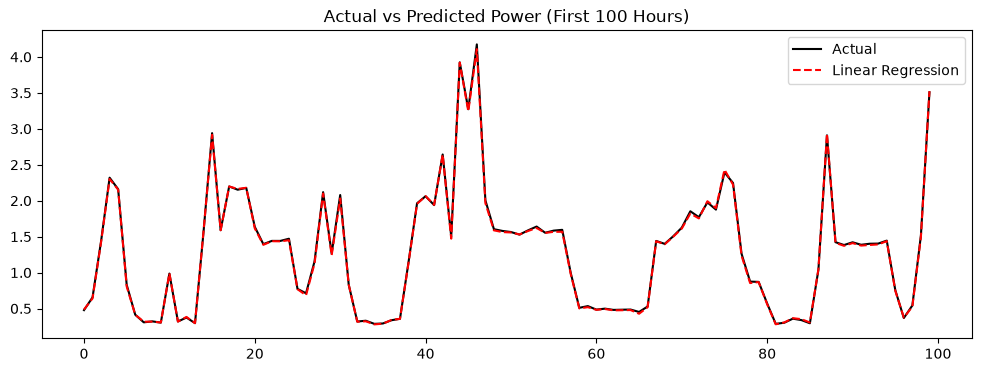

In [125]:
plt.figure(figsize=(12, 4))
plt.plot(y_test.values[:100], label='Actual', color='black')
plt.plot(lr_pred[:100], label='Linear Regression', color='red', linestyle='--')
plt.title('Actual vs Predicted Power (First 100 Hours)')
plt.legend()
plt.show()

### K-Means Clustering

In [126]:
cluster_cols = ['Global_active_power', 'Global_intensity', 'Voltage', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
X_c = df_hourly[cluster_cols]

In [127]:
c_scaler = StandardScaler()
X_c_s = c_scaler.fit_transform(X_c)

In [128]:
wcss = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_c_s)
    wcss.append(km.inertia_)

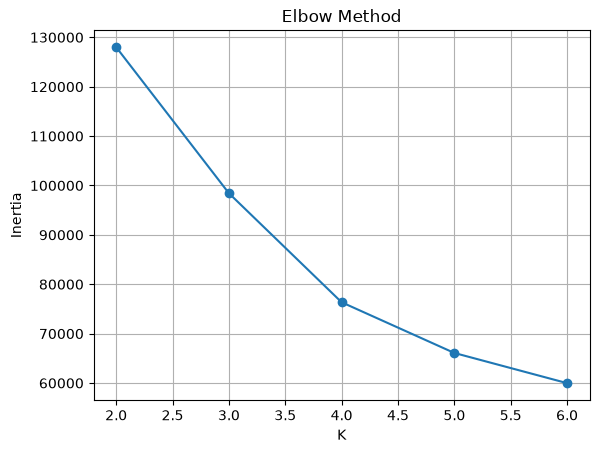

In [129]:
plt.plot(range(2, 7), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [130]:
km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df_hourly['Cluster'] = km_final.fit_predict(X_c_s)

In [131]:
df_hourly.groupby('Cluster')[cluster_cols].mean()

,Global_active_power,Global_intensity,Voltage,Sub_metering_1,Sub_metering_2,Sub_metering_3
Cluster,,,,,,
0,0.527672,2.282795,241.704911,0.201599,0.463861,1.728767
1,1.915495,8.032085,239.494799,2.533572,0.809875,14.613366
2,3.072400,13.052016,238.414791,3.624549,21.137690,10.791215


In [132]:
power_ranks = df_hourly.groupby('Cluster')['Global_active_power'].mean().sort_values().index
label_map = {
    power_ranks[0]: 'Low Usage',
    power_ranks[1]: 'Normal Usage',
    power_ranks[2]: 'High / Peak Usage'
}
label_map

{np.int32(0): 'Low Usage',
 np.int32(1): 'Normal Usage',
 np.int32(2): 'High / Peak Usage'}

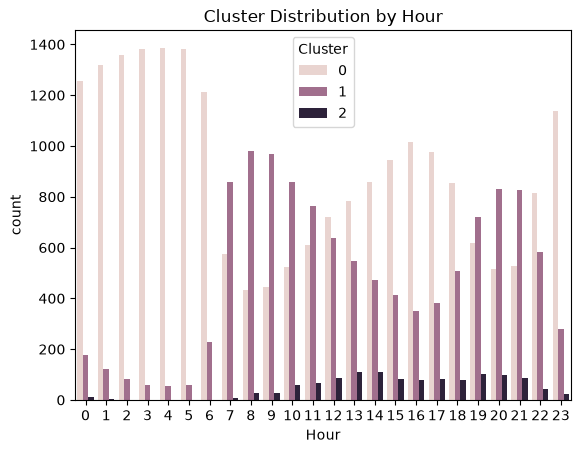

In [133]:
sns.countplot(data=df_hourly, x='Hour', hue='Cluster')
plt.title('Cluster Distribution by Hour')
plt.show()

In [134]:
def ask_energy_prediction(hour, current_amps, voltage=240.0, ac_heater_on=True, is_weekend=0, month=10):
    sub3 = 18.0 if ac_heater_on else 0.0
    sub1 = 1.0
    sub2 = 1.0
    reactive = 0.12
    day_of_week = 5 if is_weekend else 2
    
    user_data = pd.DataFrame([[reactive, voltage, current_amps, sub1, sub2, sub3, hour, day_of_week, month, is_weekend]], columns=features)
    user_data_scaled = scaler.transform(user_data)
    
    predicted_kw = lr.predict(user_data_scaled)[0]
    
    cluster_input = pd.DataFrame([[predicted_kw, current_amps, voltage, sub1, sub2, sub3]], columns=cluster_cols)
    cluster_id = km_final.predict(c_scaler.transform(cluster_input))[0]
    
    status = label_map.get(cluster_id, "Normal Usage")
    
    print("--- EnergyWise Prediction Result ---")
    print(f"Estimated Power Consumption : {predicted_kw:.2f} kW")
    print(f"Usage Category              : {status}")
    print(f"Estimated 1-Hour Energy Cost: Rs. {(predicted_kw * 7.5):.2f} (@ Rs. 7.5/kWh)")

In [135]:
# User asks: "What will my power be at 8 PM (Hour 20) with 10 Amps current and AC ON?"
ask_energy_prediction(hour=20, current_amps=10.0, ac_heater_on=True)


--- EnergyWise Prediction Result ---
Estimated Power Consumption : 2.40 kW
Usage Category              : Normal Usage
Estimated 1-Hour Energy Cost: Rs. 18.00 (@ Rs. 7.5/kWh)
